# Defining a Bayesian model with modelgami

A modelgami model is a **prior** and a **likelihood**, a paragami pattern for the parameters, the data and the hyperparameters. The prior and the likelihood are the same kind of object, a data-generating process (`DGP`): a log density and a sampler of one value given some conditioning arguments, either of which may be missing. Their functions take the value they describe first. They are ordinary JAX functions on **dicts of arrays**; there is no modelling language.

| | log density | sampler |
|---|---|---|
| prior, a `DGP` | `eval_log_density(params, hyper)` | `draw(key, hyper) -> params` |
| likelihood, a `DGP` | `eval_log_density(data, params, hyper)` | `draw(key, data, params, hyper) -> data` |
| exchangeable likelihood, an `ExchangeableDGP` | `eval_log_density_one(datum, params, hyper)` | `draw_one(key, datum, params, hyper)` |

The example is a robust regression: $y_n \\sim \\text{Student-}t_\\nu(x_n^\\top \\beta, \\sigma)$, with priors $\\beta \\sim N(0, s^2 I)$, $\\sigma \\sim \\text{Exponential}(1)$ and $\\nu \\sim \\text{Gamma}(2, 0.1)$. The observations are exchangeable, so it is an `ExchangeableModel`.

Run `./setup_venv.sh` in this folder once and register the kernel it prints; this notebook uses that kernel ("Python (modelgami)").

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from jax.scipy import stats

import paragami as pg
import modelgami as mg
from modelgami.testing import check_model_contract

jax.config.update("jax_enable_x64", True)

## Simulated data

Exchangeable data are an array of N data: a dict of arrays that all share a leading observation axis. Anything shared by every observation goes in the hyperparameters.

In [2]:
n, p = 200, 3
k1, k2 = jax.random.split(jax.random.PRNGKey(0))
X = jnp.concatenate([jnp.ones((n, 1)), jax.random.normal(k1, (n, p - 1))], axis=1)
beta_true = jnp.array([1.0, -2.0, 0.5])
y = X @ beta_true + 0.7 * jax.random.t(k2, 4.0, (n,))
data = {"x": X, "y": y}

## The model

In [3]:
params_pattern = pg.PatternDict(
    beta=pg.NumericVectorPattern(p),
    sigma=pg.NumericScalarPattern(lb=0.0),
    nu=pg.NumericScalarPattern(lb=0.0),
)
hyper = {"beta_scale": 5.0}

def eval_log_prior(params, hyper):
    return (stats.norm.logpdf(params["beta"], 0.0, hyper["beta_scale"]).sum()
            + stats.expon.logpdf(params["sigma"])
            + stats.gamma.logpdf(params["nu"], 2.0, scale=10.0))

def draw_prior(key, hyper):
    kb, ks, kn = jax.random.split(key, 3)
    return {
        "beta": hyper["beta_scale"] * jax.random.normal(kb, (p,)),
        "sigma": jax.random.exponential(ks),
        "nu": 10.0 * jax.random.gamma(kn, 2.0),
    }

def eval_log_lik_one(datum, params, hyper):
    # One observation: datum = {"x": (p,), "y": ()}
    z = (datum["y"] - datum["x"] @ params["beta"]) / params["sigma"]
    return stats.t.logpdf(z, params["nu"]) - jnp.log(params["sigma"])

def draw_one(key, datum, params, hyper):
    # A new y for one observation; its covariates are kept.
    return {"y": datum["x"] @ params["beta"] + params["sigma"] * jax.random.t(key, params["nu"])}

model = mg.ExchangeableModel(
    name="robust_regression",
    params_pattern=params_pattern,
    prior=mg.DGP(eval_log_density=eval_log_prior, draw=draw_prior),
    likelihood=mg.ExchangeableDGP(eval_log_density_one=eval_log_lik_one, draw_one=draw_one),
    data=data,
    hyper=hyper,
)
model

<ExchangeableModel robust_regression: free dimension 5>

## The same likelihood as a class

A DGP can also be a subclass with the functions as methods. The two forms are interchangeable. A function that isn't defined raises `NotImplementedError`; here the class has no sampler.

In [4]:
class StudentTRegression(mg.ExchangeableDGP):
    def eval_log_density_one(self, datum, params, hyper):
        return eval_log_lik_one(datum, params, hyper)

model_cls = mg.ExchangeableModel(params_pattern=params_pattern, prior=model.prior,
                                 likelihood=StudentTRegression(), data=data, hyper=hyper)
params = params_pattern.draw_random(jax.random.PRNGKey(1))
print(model.eval_log_lik(params), model_cls.eval_log_lik(params))
try:
    model_cls.draw_data(jax.random.PRNGKey(0), params)
except NotImplementedError as e:
    print("NotImplementedError:", e)

-618.904782579757 -618.904782579757
NotImplementedError: StudentTRegression has no sampler


## Log densities

The model's job is to combine the prior and the likelihood: `eval_log_prior`, `eval_log_lik` and `eval_log_joint` take the folded parameters (a dict). The data and hyperparameters are arguments too, defaulting to the model's own, so you can evaluate the model on other data or differentiate with respect to the hyperparameters.

In [5]:
print("log joint:", model.eval_log_joint(params))
print("first 50 observations:", model.eval_log_joint(params, data={"x": X[:50], "y": y[:50]}))
print("d log joint / d beta_scale:", jax.grad(lambda h: model.eval_log_joint(params, hyper=h))(hyper)["beta_scale"])

log joint: -634.6051025959725


first 50 observations: -168.045487068126


d log joint / d beta_scale: -0.5884332232924233


## Constrained and unconstrained parameters

Samplers and optimizers work on $\mathbb{R}^d$. `mg.free_dgp(dgp, pattern)` turns a distribution of a constrained value into the same distribution of its free vector, adding the log Jacobian to the log density (and `mg.folded_dgp` goes back). Only the prior is a density over the parameters, so the unconstrained target is the free prior plus the likelihood: that is `eval_free_log_joint`.

In [6]:
free_prior = mg.free_dgp(model.prior, params_pattern)
x = params_pattern.folded_to_free(params)
print("free dimension:", params_pattern.get_free_length())
print("free prior:", free_prior.eval_log_density(x, hyper),
      " = prior + log Jacobian:", model.eval_log_prior(params) + params_pattern.free_to_folded_log_abs_det(x))
print("free log joint:", model.eval_free_log_joint(x))
print("a free prior draw:", free_prior.draw(jax.random.PRNGKey(2), hyper))

free dimension: 5
free prior: -15.575966982235933  = prior + log Jacobian: -15.575966982235933
free log joint: -634.480749561993


a free prior draw: [-1.39687047 -4.7854548   4.17887804  1.51938898  3.13762516]


In [7]:
grad = jax.jit(jax.grad(model.eval_free_log_joint))
hess = jax.jit(jax.hessian(model.eval_free_log_joint))
print("gradient:", grad(x))
print("Hessian-vector product:", mg.make_hvp(model.eval_free_log_joint)(x, jnp.ones_like(x)))
print("Hessian diagonal:", jnp.diag(hess(x)))

gradient: [ 45.89937019 -24.66707056   5.52571989 -41.14248556  95.25834276]


Hessian-vector product: [ -62.87153872  -27.75962125  -20.59926314 -110.40617462  -45.82038807]


Hessian diagonal: [-12.30361134 -14.45690124 -16.56672389 -92.92268279 -46.90539639]


## Exchangeable data: single-observation, weighted and subset log densities

Because the likelihood is defined one observation at a time, an `ExchangeableModel` can evaluate it observation by observation, with data weights, or on a minibatch.

In [8]:
singleobs = model.eval_log_lik_singleobs(params)
print("single-observation shape:", singleobs.shape, "  sum matches eval_log_lik:",
      jnp.allclose(singleobs.sum(), model.eval_log_lik(params)))

# Weighted log joint; the gradient in the weights is each observation's influence.
w = jnp.ones(model.n_obs)
influence = jax.grad(lambda w: model.eval_log_joint(params, weights=w))(w)
print("d log joint / d w equals the single-observation values:", jnp.allclose(influence, singleobs))

# A minibatch, with the likelihood scaled by N / batch size to be unbiased.
idx = jnp.arange(20)
print("subset estimate:", model.eval_log_joint_subset(params, idx), "  full:", model.eval_log_joint(params))

# Nonparametric bootstrap weights.
print("bootstrap log joint:", model.eval_log_joint(params, weights=model.draw_np_bootstrap_weights(jax.random.PRNGKey(2))))

single-observation shape: (200,)   sum matches eval_log_lik: True


d log joint / d w equals the single-observation values: True


subset estimate: -644.1995154437851   full: -634.6051025959725


bootstrap log joint: -635.2355921208019


## Simulation

`draw_prior` draws parameters, and `draw_data` draws a full data set from `draw_one`. `draw_joint` draws both, and `draw_marginal_data` draws data from their prior predictive distribution.

In [9]:
keys = jax.random.split(jax.random.PRNGKey(3), 500)
prior_draws = jax.vmap(model.draw_prior)(keys)
print({k: v.shape for k, v in prior_draws.items()})

sim_params, sim_data = model.draw_joint(jax.random.PRNGKey(4))
print("simulated data keys:", list(sim_data), " y shape:", sim_data["y"].shape)

{'beta': (500, 3), 'nu': (500,), 'sigma': (500,)}


simulated data keys: ['x', 'y']  y shape: (200,)


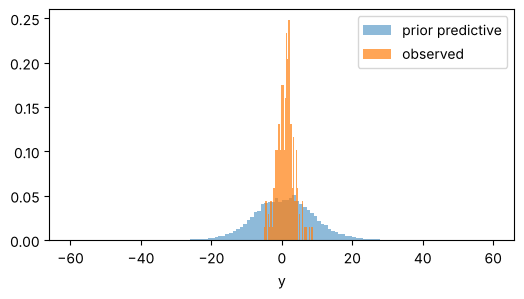

In [10]:
y_rep = jax.vmap(lambda k: model.draw_marginal_data(k)["y"])(jax.random.split(jax.random.PRNGKey(5), 200))
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.clip(np.asarray(y_rep).ravel(), -60, 60), bins=120, density=True, alpha=0.5, label="prior predictive")
ax.hist(np.asarray(y), bins=40, density=True, alpha=0.7, label="observed")
ax.set_xlabel("y"); ax.legend(); plt.show()

## Checking the model

`check_model_contract` checks that the free and folded log densities and the exchangeable extras agree with each other, and that the samplers run. Parameter values are checked by paragami.

In [11]:
ok, message = params_pattern.validate_folded(dict(params, sigma=-1.0))
print(ok, "...", message[-45:])
check_model_contract(model)

False ... 'sigma'] values must be > lb = 0.0 (min -1.0)


True

## Optional: an exchangeable likelihood from distributions

To write an exchangeable likelihood once and get both its density and its sampler, return the observation's distributions (NumPyro or TFP). A NumPyro program can also be turned into a whole model with `mg.from_numpyro`.

In [12]:
likelihood = mg.exchangeable_dgp_from_distributions(
    lambda datum, params, hyper: {"y": dist.StudentT(params["nu"], datum["x"] @ params["beta"], params["sigma"])})
model_dists = mg.ExchangeableModel(params_pattern=params_pattern, prior=model.prior, likelihood=likelihood,
                                   data=data, hyper=hyper)
print(model_dists.eval_log_lik(params), model.eval_log_lik(params))
print("simulated y:", model_dists.draw_data(jax.random.PRNGKey(6), params)["y"][:3])

-618.904782579757 -618.904782579757


simulated y: [ -4.17838643 -16.74994525  -3.52236361]
